# Step 2 — Competitive Landscape of Precision Agriculture

**Sector:** Precision Agriculture  
**Reference company:** John Deere

## Objective

We analyse the patent families selected in Step 0 to investigate:

1. How concentrated inventive activity is and how concentration evolves.
2. Who the leading applicants, incumbents, and entrants are.
3. Which technological subfields are growing.
4. Which external forces shape the sector.

Patent-family indicators describe inventive activity, not sales or market shares.

## 1. Setup and analytical scope

The analysis uses the Step 0 selection.

- **Database:** PATSTAT, production environment.
- **Observation period:** 2000–2022.
- **Invention unit:** DOCDB patent family.
- **Family year:** the year assigned in Step 0.
- **Incumbent/entrant split:** 2013.
- **Concentration windows:** three years.
- **Main applicant table:** 30 applicants.

An entrant is first observed in the selected field from 2013 onwards,
not necessarily a newly founded company.

Original applicant names are preserved throughout the analysis.

In [1]:
%pip install -q cleanco pycountry


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import unicodedata

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pycountry

from cleanco import basename
from scipy import stats
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
PROJECT_DIR = Path("/home/jovyan/team-38-PA")

STEP0_NB = (PROJECT_DIR / "notebooks" / "Step0_validation.ipynb")

GOLD_STANDARD_FILE = (PROJECT_DIR / "notebooks" / "PATSTAT_500_label_datav4.csv")

ENV = "PROD"
SECTOR_NAME = "Precision Agriculture"

YEAR_MIN = 2000
YEAR_MAX = 2022
LAST_COMPLETE_YEAR = 2022

SPLIT_YEAR = 2013
WINDOW = 3
TOP_N = 30

assert YEAR_MIN <= LAST_COMPLETE_YEAR <= YEAR_MAX
assert YEAR_MIN <= SPLIT_YEAR <= LAST_COMPLETE_YEAR
assert WINDOW > 0
assert TOP_N > 0

if not STEP0_NB.is_file():
    raise FileNotFoundError(STEP0_NB)

print(f"Sector: {SECTOR_NAME}")
print(f"Observation period: {YEAR_MIN}–{YEAR_MAX}")
print(f"Gold standard found: {GOLD_STANDARD_FILE.is_file()}")

Sector: Precision Agriculture
Observation period: 2000–2022
Gold standard found: True


In [4]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

print(f"PATSTAT client initialised in {ENV} mode.")

PATSTAT client initialised in PROD mode.


## 2. Patent families and applicant data

### 2.1 Reusing the Step 0 selection

We execute the Step 0 code up to the definition of `selected_families`,
using a separate namespace.

This preserves the technological scope previously defined for the project.

The previous analysis returned 5,181 families. This is a reference count
to check, not a result assumed in advance.

In [5]:
step0_notebook = json.loads(STEP0_NB.read_text(encoding="utf-8"))

step0_code = [
    "".join(cell["source"])
    for cell in step0_notebook["cells"]
    if cell["cell_type"] == "code"]

selection_cell = next(
    (index for index, source in enumerate(step0_code)
    if "selected_families = " in source),
    None,)

if selection_cell is None:
    raise ValueError(
        "Could not locate selected_families in the Step 0 notebook.")

step0 = {}

for source in step0_code[:selection_cell + 1]:
    exec(source, step0)

selected_families = step0["selected_families"]

step0_settings = (
    step0["ENV"],
    step0["YEAR_MIN"],
    step0["YEAR_MAX"],)

if step0_settings != (ENV, YEAR_MIN, YEAR_MAX):
    raise ValueError(
        f"Step 0 settings differ: {step0_settings}")


Configuration: /home/jovyan/team-38-PA/config/sector_PA_FINAL.yaml
Environment: PROD
Period: 2000 - 2022
Output directory: /home/jovyan/team-38-PA/notebooks/outputs/step0
Specific phrases: 7
Enabling technologies: 51
PA functions: 46
Topical exclusions: 23
PATSTAT client initialized: PROD
Representative applications prepared.
Family-level keyword flags prepared.
CPC flags prepared.
IPC flags prepared.
Representative-application classification exclusions prepared.
Representative-application topical exclusions and protected CPC prepared.
Combined family-level evidence prepared.
Final family-level query: R1 OR R2 OR R3


In [6]:
fam = patstat.df(
    db.query(
        selected_families.c.fam_id.label("unit_id"),
        selected_families.c.family_year.label("year"),))

if fam.empty:
    raise ValueError("The selection returned no families.")

if fam[["unit_id", "year"]].isna().any().any():
    raise ValueError("Missing family identifiers or years.")

if fam["unit_id"].duplicated().any():
    raise ValueError("Repeated family identifiers.")

fam = fam.astype({
    "unit_id": int,
    "year": int,})

if not fam["year"].between(YEAR_MIN, YEAR_MAX).all():
    raise ValueError("Family years fall outside the observation period.")

fam_ids = fam["unit_id"].tolist()
year_of = fam.set_index("unit_id")["year"]

print(f"Selected families: {len(fam):,}")
print(f"Difference from previous count: {len(fam) - 5181:+,}")

Selected families: 5,181
Difference from previous count: +0


### 2.2 Linking families to applicants and CPC codes

For each selected family, we retrieve:

- Applicant identifiers and PATSTAT standardised names.
- Applicant sector labels and countries.
- CPC classifications.

Only applicant links are retained (`applt_seq_nr > 0`).
Inventor-only links are excluded.

A family may have multiple applicants and multiple classification codes.
Repeated family identifiers in these tables are therefore expected.

In [7]:
q_applicants = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        TLS206_PERSON.psn_id,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.psn_sector,
        func.trim(
            TLS206_PERSON.person_ctry_code
        ).label("ctry"),)
    .join(
        TLS207_PERS_APPLN,
        TLS207_PERS_APPLN.appln_id
        == TLS201_APPLN.appln_id,)
    .join(
        TLS206_PERSON,
        TLS206_PERSON.person_id
        == TLS207_PERS_APPLN.person_id,)
    .filter(
        TLS201_APPLN.docdb_family_id.in_(fam_ids),
        TLS207_PERS_APPLN.applt_seq_nr > 0,)
    .distinct())

raw_sector = patstat.df(q_applicants)

if raw_sector.empty:
    raise ValueError("No applicant records retrieved.")

raw_sector.insert(
    1,
    "year",
    raw_sector["unit_id"].map(year_of),)

# Preserve the source name; only boundary whitespace is removed.
raw_sector["psn_name"] = (
    raw_sector["psn_name"]
    .astype("string")
    .str.strip())

print(f"Applicant records retrieved: {len(raw_sector):,}")

Applicant records retrieved: 9,898


In [8]:
q_cpc = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        func.replace(
            TLS224_APPLN_CPC.cpc_class_symbol,
            " ",
            "",
        ).label("cpc"),)
    .join(
        TLS224_APPLN_CPC,
        TLS224_APPLN_CPC.appln_id
        == TLS201_APPLN.appln_id,)
    .filter(
        TLS201_APPLN.docdb_family_id.in_(fam_ids))
    .distinct())

family_cpc = patstat.df(q_cpc)
family_cpc.insert(1,"year",family_cpc["unit_id"].map(year_of),)

print("Families with retrieved CPC records:",f"{family_cpc['unit_id'].nunique():,}",)

Families with retrieved CPC records: 4,798


### 2.3 Coverage and interpretation of the raw data

We distinguish:

- **Selected families:** the inventions in the Step 0 selection.
- **Family-person records:** retrieved links between families and
  PATSTAT applicant records.
- **Distinct PATSTAT names:** different name strings before harmonisation.

Distinct names are not yet a count of independent competitors.

We report both applicant-record coverage and usable-name coverage.
A family with applicant records may still lack a non-empty applicant name.

Families without non-empty CPC codes cannot contribute to CPC-based
subfield analysis. Later selection of specific CPC groups may reduce
coverage further.

In [9]:
valid_name = (raw_sector["psn_name"].fillna("").ne(""))
valid_cpc = (family_cpc["cpc"].fillna("").str.strip().ne(""))

coverage = pd.DataFrame({
    "families": [
        len(fam),
        raw_sector["unit_id"].nunique(),
        raw_sector.loc[valid_name, "unit_id"].nunique(),
        family_cpc.loc[valid_cpc, "unit_id"].nunique(),
    ],}, index=[
    "Step 0 selection",
    "With applicant records",
    "With non-empty applicant names",
    "With non-empty CPC codes",])

coverage["coverage (%)"] = (coverage["families"] / len(fam) * 100)

display(coverage.round(2))
print(f"Family-person records: {len(raw_sector):,}")
print("Distinct non-empty PATSTAT names:",f"{raw_sector.loc[valid_name, 'psn_name'].nunique():,}",)
print("\nPATSTAT sector labels — record counts:")
display(raw_sector["psn_sector"].value_counts(dropna=False).rename_axis("PATSTAT sector").to_frame("records"))

,families,coverage (%)
Step 0 selection,5181,100.00
With applicant records,5168,99.75
With non-empty applicant names,5168,99.75
With non-empty CPC codes,4798,92.61


Family-person records: 9,898
Distinct non-empty PATSTAT names: 3,728

PATSTAT sector labels — record counts:


,records
PATSTAT sector,
COMPANY,5161
UNKNOWN,2005
INDIVIDUAL,1710
UNIVERSITY,690
GOV NON-PROFIT,210
GOV NON-PROFIT UNIVERSITY,69
,45
COMPANY GOV NON-PROFIT UNIVERSITY,3
COMPANY UNIVERSITY,3


## 3. Applicant name cleaning and harmonisation

### 3.1 General name cleaning

We first standardise the written form of applicant names:

- normalise Unicode characters and accents;
- standardise capitalisation;
- remove balanced parentheses and their contents;
- remove recognised legal forms using cleanco;
- remove remaining legal-form words at the boundaries;
- standardise punctuation and whitespace.

Parenthetical removal is an explicit simplification convention: it can remove locations, expanded names, or organisational descriptions.

Non-Latin characters are preserved rather than discarded.
If cleaning would produce an empty name, the original name is retained.

In [10]:
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "HOLDINGS", 
    "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS",
    "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA",
    "OY", "OYJ", "KK", "KABUSHIKI", "KAISHA",
    "LTDA", "PTY", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
    "SARL", "SRO", "SL", "SLU", "LLP", "PTE",
    "BHD", "SDN", "OOO", "OAO", "ZAO", "PJSC", "JSC",
    "EURL", "SASU",}

def clean_name_details(name):
    """Return the cleaned name and whether the original was preserved."""
    if pd.isna(name):
        return "", False
    original = str(name).strip()
    if not original:
        return "", False
    text = (
        original
        .replace("ß", "ss")
        .replace("Ø", "O")
        .replace("ø", "o")
        .replace("Æ", "AE")
        .replace("æ", "ae"))
    
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    ).upper()

    # Remove balanced parentheses, including nested parentheses.
    while re.search(r"\([^()]*\)", text):
        text = re.sub(r"\([^()]*\)", " ", text)
    
    text = " ".join(text.split())

    # Keep punctuation available while cleanco recognises legal forms.
    for _ in range(5):
        candidate = basename(text).strip()
        if not candidate or candidate == text:
            break
        text = candidate
    
    # Standardise punctuation without deleting non-Latin scripts.
    text = re.sub(r"[^\w\s]", " ", text)
    text = text.replace("_", " ")

    words = text.split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()

    while words and words[0] in LEGAL_FORMS:
        words.pop(0)

    # Explicit naming convention.
    if words and words[0] == "THE":
        words.pop(0)

    cleaned = " ".join(words)
    if not cleaned:
        return original, True
    return cleaned, False


def clean_name(name):
    """Return the general-cleaning label."""
    return clean_name_details(name)[0]

In [11]:
name_audit = (
    raw_sector.loc[
        raw_sector["psn_name"].notna()
        & raw_sector["psn_name"].ne(""),
        ["psn_name"],]
    .drop_duplicates()
    .copy())

cleaning_results = [clean_name_details(name) for name in name_audit["psn_name"]]

name_audit["cleaned_name"] = [result[0] for result in cleaning_results]
name_audit["original_preserved"] = [result[1] for result in cleaning_results]

families_by_name = (raw_sector.groupby("psn_name")["unit_id"].nunique())

name_audit["families"] = (name_audit["psn_name"].map(families_by_name))

print(f"Original names: {name_audit['psn_name'].nunique():,}")
print(f"Distinct cleaned names: {name_audit['cleaned_name'].nunique():,}")
print("Names preserved because cleaning would be empty:",int(name_audit["original_preserved"].sum()),)

cleaning_changes = (
    name_audit.loc[
        name_audit["psn_name"] != name_audit["cleaned_name"],
        ["psn_name", "cleaned_name", "families"],]
    .sort_values("families", ascending=False))

display(cleaning_changes.drop_duplicates(["psn_name", "cleaned_name"]).head(8).reset_index(drop=True))

Original names: 3,728
Distinct cleaned names: 3,402
Names preserved because cleaning would be empty: 0


,psn_name,cleaned_name,families
0,KUBOTA CORPORATION,KUBOTA,407
1,CNH (CASE NEW HOLLAND) BELGIUM,CNH BELGIUM,97
2,"YANMAR HOLDINGS CO., LTD.",YANMAR,96
3,"Yanmar Holdings Co., Ltd.",YANMAR,94
4,YANMAR HOLDINGS CO LTD,YANMAR,93
5,YANMAR COMPANY,YANMAR,86
6,AGCO CORPORATION,AGCO,79
7,ISEKI & CO,ISEKI,78


### 3.2 Country-name removal

After general cleaning, some company names still contain geographical
qualifiers, such as CNH BELGIUM.

We remove recognised country expressions at the end of cleaned company names.
Country words elsewhere in the name are preserved.

Country names come from the pycountry database, supplemented with selected
language variants and abbreviations. AMERICA, NORTH AMERICA, and SOUTH AMERICA
are included as explicit regional additions. Cities and provinces are excluded.
The rule is intended for firms, not individuals or academic institutions.

In [12]:
# Applicant types
def applicant_type(psn_sector):
    sector = "" if pd.isna(psn_sector) else str(psn_sector).upper()
    if any(word in sector for word in [
        "UNIVERSITY", "ACADEMY", "COLLEGE", "FACULTY"]):
        return "university"
    if "HOSPITAL" in sector:
        return "hospital"
    if "GOV" in sector:
        return "government / non-profit"
    if "INDIVIDUAL" in sector:
        return "individual"
    if "COMPANY" in sector or "FIRM" in sector:
        return "firm"
    return "unknown"

def most_frequent(values):
    counts = values.value_counts()
    return sorted(counts[counts.eq(counts.max())].index)[0]

type_records = raw_sector[["psn_name", "psn_sector"]].copy()
type_records["record_type"] = (type_records["psn_sector"].map(applicant_type))

known_types = type_records.loc[type_records["record_type"].ne("unknown")]
type_by_name = (known_types.groupby("psn_name")["record_type"].agg(most_frequent))

name_audit["type"] = (name_audit["psn_name"].map(type_by_name).fillna("unknown"))

# Country expressions
def country_key(value):
    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)).upper()
    return " ".join(re.sub(r"[^\w\s]", " ", text).split())

COUNTRY_EXPRESSIONS = set()

for country in pycountry.countries:
    for attribute in ("name", "official_name", "common_name"):
        value = getattr(country, attribute, None)

        if value:
            COUNTRY_EXPRESSIONS.add(country_key(value))

COUNTRY_EXPRESSIONS.update({
    "DEUTSCHLAND", "GERMANY",
    "ITALIA", "ITALY",
    "DO BRASIL", "BRASIL", "BRAZIL",
    "SCHWEIZ", "SUISSE", "SWITZERLAND",
    "OESTERREICH", "OSTERREICH", "AUSTRIA",
    "NEDERLAND", "NETHERLANDS",
    "BELGIE", "BELGIQUE", "BELGIUM",
    "ESPANA", "SPAIN",
    "UK", "U K", "UNITED KINGDOM", "GREAT BRITAIN",
    "USA", "U S A", "U S", "UNITED STATES",
    "UNITED STATES OF AMERICA",
    "SOUTH KOREA", "NORTH KOREA",
    "PEOPLES REPUBLIC OF CHINA",
    "PEOPLE S REPUBLIC OF CHINA",
    "AMERICA", "NORTH AMERICA", "SOUTH AMERICA",})

ordered_countries = sorted(COUNTRY_EXPRESSIONS,key=lambda value: (-len(value.split()), -len(value)),)

FINAL_COUNTRY_PATTERN = re.compile(
    r"(?<!\w)(?:"
    + "|".join(re.escape(value) for value in ordered_countries)
    + r")$"
)


def remove_country_suffix(cleaned_name):
    """Remove a recognised geographical suffix from a cleaned name."""
    original = str(cleaned_name).strip()
    text = original

    while True:
        match = FINAL_COUNTRY_PATTERN.search(text)
        if match is None:
            break
        candidate = text[:match.start()].strip()
        # Preserve names that would become empty or purely numeric.
        if not candidate or not any(c.isalpha() for c in candidate):
            break
        text = candidate
    return text


name_audit["after_country_removal"] = [
    remove_country_suffix(name) if kind == "firm" else name
    for name, kind in zip(
        name_audit["cleaned_name"],
        name_audit["type"],)]


# Inspect actual geographical changes
country_changes = (
    name_audit.loc[
        name_audit["cleaned_name"]
        != name_audit["after_country_removal"],
        ["psn_name",
         "cleaned_name",
         "after_country_removal",
         "families",],]
    .sort_values("families", ascending=False)
    .reset_index(drop=True))

print(f"Original-name rows changed: {len(country_changes):,}")
display(country_changes[["cleaned_name", "after_country_removal", "families"]].head(15))

Original-name rows changed: 27


,cleaned_name,after_country_removal,families
0,CNH INDUSTRIAL AMERICA,CNH INDUSTRIAL,306
1,CNH BELGIUM,CNH,97
2,CNH INDUSTRIAL CANADA,CNH INDUSTRIAL,77
3,CNH AMERICA,CNH,45
4,CNH INDUSTRIAL ITALIA,CNH INDUSTRIAL,33
5,CNH CANADA,CNH,9
6,CNH ITALIA,CNH,7
7,CNH INDUSTRIAL BRASIL,CNH INDUSTRIAL,6
8,CNH INDUSTRIAL SWEDEN,CNH INDUSTRIAL,5
9,CNH IND AMERICA,CNH IND,3


### 3.3 Prefix-based name linking

After cleaning and country-name removal, we link longer firm names to shorter firm names already present in the dataset.

For example, CNH INDUSTRIAL can be linked to CNH when both are present.

The shorter name must:
- contain at least three characters;
- occur as a complete-word prefix;
- belong to an applicant classified as a firm;
- not consist entirely of generic words.

Only firms are eligible, both as names to be linked and as reference names.
Other applicant types remain unchanged.

This rule is automatic and does not contain a predefined list of companies.
However, a common prefix is not proof of corporate identity: incorrect
consolidations remain possible and must be assessed during validation.

Names such as JOHN DEERE and DEERE are not necessarily linked by this rule,
because neither is a prefix of the other.

In [18]:
EXCEPTIONS = {
    "GENERAL", "INTERNATIONAL", "NATIONAL", "UNITED",
    "TECHNOLOGY", "TECHNOLOGIES", "SYSTEMS",
    "SCIENCE", "SCIENCES", "RESEARCH", "INDUSTRIAL",
    "INDUSTRIES", "ENGINEERING", "AGRICULTURE",
    "AGRICULTURAL", "GROUP", "HOLDINGS",
    "UNIVERSITY", "INSTITUTE", "CENTER", "CENTRE",
    "CHINA", "CHINESE", "AMERICAN",
}


def build_firm_prefix_map(firm_names):
    """Link firm names to existing complete-word firm prefixes."""
    names = {
        str(name).strip()
        for name in firm_names
        if pd.notna(name) and str(name).strip()}

    anchors = {
        name for name in names
        if len(name) >= 3
        and not all( word in EXCEPTIONS for word in name.split())}

    mapping = {}

    for name in sorted(names):
        words = name.split()
        target = name

        # Prefer the shortest eligible existing prefix.
        for length in range(1, len(words)):
            prefix = " ".join(words[:length])
            if prefix in anchors:
                target = prefix
                break
        mapping[name] = target
    return mapping


firm_mask = name_audit["type"].eq("firm")

prefix_map = build_firm_prefix_map(name_audit.loc[firm_mask, "after_country_removal"])

name_audit["after_prefix_linking"] = (name_audit["after_country_removal"])

name_audit.loc[firm_mask, "after_prefix_linking"] = (
    name_audit.loc[firm_mask, "after_country_removal"].map(prefix_map))

prefix_changes = (
    name_audit.loc[
        name_audit["after_country_removal"]
        != name_audit["after_prefix_linking"],
        [
            "psn_name",
            "after_country_removal",
            "after_prefix_linking",
            "families",],].sort_values("families", ascending=False))

print(f"Original-name rows changed: {len(prefix_changes):,}")

display(
    prefix_changes
    .drop_duplicates(["after_country_removal", "after_prefix_linking"])
    [["after_country_removal", "after_prefix_linking", "families"]].head(20).reset_index(drop=True))

Original-name rows changed: 61


,after_country_removal,after_prefix_linking,families
0,CNH INDUSTRIAL,CNH,306
1,YANMAR POWER TECHNOLOGY,YANMAR,76
2,AGCO INTERNATIONAL,AGCO,42
3,BASF AGRO TRADEMARKS,BASF,38
4,TRIMBLE NAVIGATION,TRIMBLE,34
5,CNH MANAGEMENT,CNH,16
6,BAYER CROPSCIENCE,BAYER,13
7,TOPCON POSITIONING SYSTEMS,TOPCON,12
8,AGXEED HOLDING,AGXEED,8
9,AMVAC CHEMICAL,AMVAC,8


In [19]:
deere_candidates = name_audit.loc[
    name_audit["psn_name"].str.contains(
        r"DEERE|DIER|迪尔|ДИР ЭНД",
        case=False,
        regex=True,
        na=False,),
    [   "psn_name",
        "cleaned_name",
        "after_country_removal",
        "after_prefix_linking",
        "families",],].sort_values("families", ascending=False)

with pd.option_context("display.max_colwidth", None):
    display(deere_candidates.reset_index(drop=True))

,psn_name,cleaned_name,after_country_removal,after_prefix_linking,families
0,JOHN DEERE,JOHN DEERE,JOHN DEERE,JOHN DEERE,495
1,迪尔公司,迪尔公司,迪尔公司,迪尔公司,51
2,DIER COMPANY,DIER,DIER,DIER,8
3,DEERE &COMPANY,DEERE,DEERE,DEERE,7
4,ДИР ЭНД КОМПАНИ,ДИР ЭНД КОМПАНИ,ДИР ЭНД КОМПАНИ,ДИР ЭНД КОМПАНИ,4
5,DEERE & COMPANY,DEERE,DEERE,DEERE,2
6,"VERHAEGHE, DIDIER",VERHAEGHE DIDIER,VERHAEGHE DIDIER,VERHAEGHE DIDIER,1
7,DEERE & CO,DEERE,DEERE,DEERE,1
8,Deere & Comoanv,DEERE COMOANV,DEERE COMOANV,DEERE COMOANV,1


### 3.5 Explicit sector mappings

After general cleaning, country-name removal, and prefix linking, we apply
explicit mappings developed for the Precision Agriculture dataset.

These mappings address:
- recognised non-Latin names;
- spelling errors and alternative names;
- canonical labels for selected applicants;
- corrections to unintended transformations introduced by general cleaning.

JOHN DEERE is the canonical label for the Deere variants.

The original name is inspected as well as the preceding label, so information
removed during earlier stages can still support a manual correction.

In [22]:
def contains_non_latin_letters(name):
    return any(
        character.isalpha()
        and "LATIN" not in unicodedata.name(character, "")
        for character in str(name))

non_latin_names = (
    name_audit.loc[
        name_audit["psn_name"].map(contains_non_latin_letters),
        ["psn_name", "after_prefix_linking", "type", "families"],
    ].sort_values("families", ascending=False).reset_index(drop=True))

print(f"Names containing non-Latin letters: {len(non_latin_names):,}")

with pd.option_context("display.max_rows", None,"display.max_colwidth", None,):
    display(non_latin_names.head(30))

Names containing non-Latin letters: 99


,psn_name,after_prefix_linking,type,families
0,迪尔公司,迪尔公司,firm,51
1,克莱米特有限责任公司,克莱米特有限责任公司,unknown,14
2,凯斯纽荷兰工业美国有限责任公司,凯斯纽荷兰工业美国有限责任公司,firm,11
3,自控解决方案股份有限公司,自控解决方案股份有限公司,firm,9
4,精密种植有限责任公司,精密种植有限责任公司,firm,7
5,凯斯纽荷兰(中国)管理有限公司,凯斯纽荷兰 管理有限公司,firm,6
6,ЗЕ КЛАЙМЕТ КОРПОРЕЙШН,ЗЕ КЛАИМЕТ КОРПОРЕИШН,firm,5
7,ДИР ЭНД КОМПАНИ,ДИР ЭНД КОМПАНИ,firm,4
8,ЗЕ КЛАЙМАТ КОРПОРЕЙШН,ЗЕ КЛАИМАТ КОРПОРЕИШН,firm,4
9,ЗЕ КЛАЙМЕТ КОРПОРЭЙШН,ЗЕ КЛАИМЕТ КОРПОРЭИШН,unknown,4


In [23]:
# Non-Latin names inherited from the previous sector implementation.
NON_LATIN_NAMES = {
    "JOHN DEERE": ["迪尔公司", "ДИР ЭНД КОМПАНИ",],
    "CLIMATE": ["克莱米特有限责任公司", "ЗЕ КЛАЙМЕТ КОРПОРЕЙШН", "ЗЕ КЛАЙМАТ КОРПОРЕЙШН", "ЗЕ КЛАЙМЕТ КОРПОРЭЙШН", "КЛАЙМЕТ ЛЛСи", "克莱米特公司",],
    "CNH": ["凯斯纽荷兰工业美国有限责任公司", "凯斯纽荷兰(中国)管理有限公司",],
    "AUTONOMOUS SOLUTIONS": ["自控解决方案股份有限公司",],
    "PRECISION PLANTING": ["精密种植有限责任公司",],
    "ZF": ["采埃孚股份公司",],
    "BASF": ["巴斯夫农化商标有限公司", "巴斯夫欧洲公司",],}

# Reverse lookup for exact original-name matching.
NON_LATIN_LOOKUP = {}

for canonical, variants in NON_LATIN_NAMES.items():
    for variant in variants:
        key = variant.strip()
        if (key in NON_LATIN_LOOKUP and NON_LATIN_LOOKUP[key] != canonical):
            raise ValueError(f"Conflicting mapping for: {key}")
        NON_LATIN_LOOKUP[key] = canonical

# Explicit corrections and canonical names.
# Corrections not already covered by the sector linking rules.
ENTITY_FIX = {
    # Reviewed name variant in the sector sample.
    "DIER": "JOHN DEERE",
    "DIER COMPANY": "JOHN DEERE",
    # Restore a meaningful token removed during generic cleaning.
    "AG LEADER TECHNOLOGY": "AG LEADER TECHNOLOGY",
    # Spelling errors not resolved by the current prefix rule.
    "RAVEN INDUDSTRIES": "RAVEN INDUSTRIES",
    "RAVEN INDUSTIRES": "RAVEN INDUSTRIES",
    # Alternative spellings of the same proposed institutional name.
    "TECHNISCHE UNIVERSITAT MUNCHEN":
        "TECHNISCHE UNIVERSITAET MUENCHEN",
    "TECHNISCHE UNIVERSITA MUNCHEN":
        "TECHNISCHE UNIVERSITAET MUENCHEN",
}

# Explicit sector consolidations, not acquisitions.
SECTOR_LINK_RULES = [
    ("JOHN DEERE", r"^(JOHN )?DEERE\b"),
    ("CNH", r"^CNH\b|^CASE$|^NEW HOLLAND\b"),
    ("YANMAR", r"^YANMAR\b"),
    ("AGCO", r"^AGCO\b"),
    ("TRIMBLE", r"^TRIMBLE\b"),
    ("BASF", r"^BASF\b"),
    ("BOSCH", r"^ROBERT BOSCH\b"),
    ("ZF", r"^ZAHNRADFABRIK FRIEDRICHSHAFEN\b|^ZF\b"),
    ("KUBOTA", r"^KUBOTA\b"),
    ("CLAAS", r"^CLAAS\b"),
    ("BAYER", r"^BAYER\b"),
    (
        "MITSUBISHI MAHINDRA AGRICULTURAL MACHINERY",
        r"^MITSUBISHI (MAHINDRA )?AGRICULTURAL MACHINERY$",
    ),
]


def apply_sector_mapping(original_name, previous_label):
    """Apply remaining corrections and explicit canonical labels."""
    original = str(original_name).strip()
    original_key = " ".join(original.upper().split())
    cleaned_original = clean_name(original)
    translated = NON_LATIN_LOOKUP.get(original)

    # Original-name checks can restore information lost during cleaning.
    correction = ENTITY_FIX.get(original_key)
    if correction is None:
        correction = ENTITY_FIX.get(cleaned_original)
    if correction is None and translated is not None:
        correction = ENTITY_FIX.get(translated, translated)

    candidate = ( correction
        if correction is not None
        else str(previous_label).strip())

    # A recognised translation must be used even if it needs no correction.
    if correction is None and translated is not None:
        candidate = translated

    probes = [
        correction
        if correction is not None
        else translated
        if translated is not None
        else cleaned_original,
        candidate,]

    for canonical, pattern in SECTOR_LINK_RULES:
        if any(re.search(pattern, probe.upper()) for probe in probes):
            return canonical

    return ENTITY_FIX.get(candidate, candidate)

In [24]:
name_audit["applicant"] = [
    apply_sector_mapping(original, previous)
    for original, previous in zip(name_audit["psn_name"], name_audit["after_prefix_linking"],)]

manual_changes = (
    name_audit.loc[
        name_audit["after_prefix_linking"]
        != name_audit["applicant"],
        [
            "psn_name",
            "after_prefix_linking",
            "applicant",
            "families",],].sort_values("families", ascending=False).reset_index(drop=True))

print(f"Original-name rows changed by manual rules: {len(manual_changes)}")

with pd.option_context("display.max_colwidth", None):
    display(manual_changes.head(20))

Original-name rows changed by manual rules: 66


,psn_name,after_prefix_linking,applicant,families
0,迪尔公司,迪尔公司,JOHN DEERE,51
1,CLAAS SELBSTFAHRENDE ERNTEMASCHINEN,CLAAS SELBSTFAHRENDE ERNTEMASCHINEN,CLAAS,46
2,ROBERT BOSCH,ROBERT BOSCH,BOSCH,32
3,AG LEADER TECHNOLOGY,LEADER TECHNOLOGY,AG LEADER TECHNOLOGY,27
4,ZAHNRADFABRIK FRIEDRICHSHAFEN,ZAHNRADFABRIK FRIEDRICHSHAFEN,ZF,27
5,克莱米特有限责任公司,克莱米特有限责任公司,CLIMATE,14
6,CLAAS TRACTOR,CLAAS TRACTOR,CLAAS,14
7,CLAAS E-SYSTEMS,CLAAS E SYSTEMS,CLAAS,13
8,CNH Industrial Italia S.p.A.,CNH INDUSTRIAL ITALIA,CNH,13
9,凯斯纽荷兰工业美国有限责任公司,凯斯纽荷兰工业美国有限责任公司,CNH,11


### 3.5 Final harmonised applicant table

We link the final harmonised names back to the original applicant records.

Patent portfolios are measured as distinct patent families: if several
original names assigned to the same applicant occur within one family,
that family is counted only once for that applicant.

Applicant type and country are summarised using the most frequent known
value across distinct applicant–family–type or applicant–family–country
combinations. Ties are resolved alphabetically.

In [25]:
final_name_map = name_audit[["psn_name", "applicant"]].copy()
if final_name_map["psn_name"].duplicated().any():
    raise ValueError("The name mapping contains duplicate original names.")

applicant_records = raw_sector.merge(
    final_name_map,
    on="psn_name",
    how="left",
    validate="many_to_one",)

# Preserve records whose original names were not included in the audit.
applicant_records["applicant"] = (applicant_records["applicant"].fillna(applicant_records["psn_name"]).astype("string").str.strip())

applicant_records = applicant_records.loc[
    applicant_records["applicant"].notna()
    & applicant_records["applicant"].ne("")].copy()
applicant_records["record_type"] = (applicant_records["psn_sector"].map(applicant_type))

def most_frequent_known(values):
    values = values.dropna().astype(str).str.strip()
    values = values.loc[
        values.ne("")
        & ~values.str.lower().isin({"unknown", "nan", "none", "<na>"})]
    if values.empty:
        return pd.NA
    return sorted(values.mode().tolist())[0]

# One record per applicant and patent family
applicant_links = (applicant_records[["unit_id", "year", "applicant"]].drop_duplicates().reset_index(drop=True))

portfolio_sizes = (applicant_links.groupby("applicant")["unit_id"].nunique().rename("families"))

# Count each family once for each observed type or country.
type_records = applicant_records[["applicant", "unit_id", "record_type"]].drop_duplicates()
country_records = applicant_records[["applicant", "unit_id", "ctry"]].drop_duplicates()
final_types = (type_records.groupby("applicant")["record_type"].agg(most_frequent_known).rename("type"))
final_countries = (country_records.groupby("applicant")["ctry"].agg(most_frequent_known).rename("country"))

applicant_summary = (
    portfolio_sizes.to_frame()
    .join(final_types)
    .join(final_countries)
    .sort_values(
        ["families", "applicant"],
        ascending=[False, True],))

applicant_summary["type"] = (applicant_summary["type"].fillna("unknown"))

# Final sector output
print("Selected period:", f"{int(fam['year'].min())}–{int(fam['year'].max())}",)
print(f"Selected patent families: {fam['unit_id'].nunique():,}")
print("Families represented in the applicant table:",f"{applicant_links['unit_id'].nunique():,}",)
print(f"Harmonised applicants: {len(applicant_summary):,}")
print("\nTop 30 applicants — final harmonisation:")
display(applicant_summary.head(30))
print("\nFamilies with multiple applicants contribute once to each ""applicant's portfolio. Portfolio counts therefore overlap.")

Selected period: 2000–2022
Selected patent families: 5,181
Families represented in the applicant table: 5,168
Harmonised applicants: 3,295

Top 30 applicants — final harmonisation:


,families,type,country
applicant,,,
JOHN DEERE,495,firm,US
CNH,430,firm,US
KUBOTA,407,firm,JP
YANMAR,202,firm,JP
AGCO,123,firm,US
CLAAS,82,firm,DE
CLIMATE,79,firm,US
ISEKI,78,firm,JP
PRECISION PLANTING,65,firm,US



Families with multiple applicants contribute once to each applicant's portfolio. Portfolio counts therefore overlap.


### 3.6 Validation 

### 3.6.1 Against the gold standard

We apply the complete harmonisation pipeline to the company names in the
gold standard.

We report pairwise precision, recall, and F1 for the final assignments.
Precision measures how often predicted links agree with the reference;
recall measures how many reference links are recovered.

In [27]:
# Load the gold standard
gold = pd.read_csv(GOLD_STANDARD_FILE,sep=None,engine="python",)

# Accept either the original column names or their renamed versions.
column_lookup = {str(column).strip().lower(): column for column in gold.columns}

name_column = next(
    (   column_lookup[key]
        for key in ("comp", "name", "psn_name")
        if key in column_lookup),None,)

group_column = next(
    (   column_lookup[key]
        for key in ("group", "gold_group")
        if key in column_lookup),None,)

if name_column is None or group_column is None:
    raise ValueError(
        "Could not identify the name and reference-group columns. "
        f"Available columns: {gold.columns.tolist()}")

gold = (
    gold[[name_column, group_column]]
    .rename(columns={
            name_column: "name",
            group_column: "gold_group",}).dropna(subset=["name", "gold_group"]).copy())

gold["name"] = gold["name"].astype(str).str.strip()
gold = gold.loc[gold["name"].ne("")].reset_index(drop=True)

# Apply the complete pipeline
gold["cleaned_name"] = gold["name"].map(clean_name)
gold["after_country_removal"] = (gold["cleaned_name"].map(remove_country_suffix))
gold_prefix_map = build_firm_prefix_map(gold["after_country_removal"].unique())
gold["after_prefix_linking"] = (gold["after_country_removal"].map(gold_prefix_map))

gold["predicted_applicant"] = [
    apply_sector_mapping(original, previous)
    for original, previous in zip(
        gold["name"],
        gold["after_prefix_linking"],)]

if (gold["predicted_applicant"].isna().any() or gold["predicted_applicant"].str.strip().eq("").any()):
    raise ValueError("Some benchmark names have no final assignment.")

# Pairwise evaluation
def count_pairs(sizes):
    return sum(int(size) * (int(size) - 1) // 2 for size in sizes)

true_positive_pairs = count_pairs(gold.groupby(["gold_group", "predicted_applicant"]).size())
predicted_pairs = count_pairs(gold.groupby("predicted_applicant").size())
reference_pairs = count_pairs(gold.groupby("gold_group").size())

precision = (
    true_positive_pairs / predicted_pairs
    if predicted_pairs else 0.0)

recall = (
    true_positive_pairs / reference_pairs
    if reference_pairs else 0.0)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0)

validation_metrics = pd.DataFrame(
    {
        "Complete harmonisation pipeline": [
            gold["gold_group"].nunique(),
            gold["predicted_applicant"].nunique(),
            precision,
            recall,
            f1,]},
    index=[
        "reference groups",
        "predicted groups",
        "precision",
        "recall",
        "F1",],)

display(
    validation_metrics.style.format(
        {
            "Complete harmonisation pipeline":
                lambda value: f"{value:,.3f}"} ))

,Complete harmonisation pipeline
reference groups,481.000
predicted groups,820.000
precision,0.969
recall,0.902
F1,0.934


### 3.6.2 Sector-specific validation: precision

We randomly sample up to 50 pairs of distinct original names assigned to the same final applicant.

Each pair is manually labelled as correct, incorrect or uncertain.

**Precision** is calculated on the manually resolved pairs.  This estimates pairwise precision among predicted links.

In [28]:
from itertools import combinations
import random

# Use one final assignment per original name.
validation_names = (
    name_audit[["psn_name", "applicant"]]
    .dropna()
    .drop_duplicates()
    .sort_values(["applicant", "psn_name"])
)

if validation_names["psn_name"].duplicated().any():
    raise ValueError("Some original names have multiple assignments.")

# Reservoir sampling: uniform sampling without storing every pair.
rng = random.Random(42)
sample_size = 50
sampled_pairs = []
total_pairs = 0

for applicant, group in validation_names.groupby("applicant"):
    names = sorted(group["psn_name"].tolist())

    for name_1, name_2 in combinations(names, 2):
        record = {
            "name_1": name_1,
            "name_2": name_2,
            "predicted_applicant": applicant,
        }

        total_pairs += 1

        if len(sampled_pairs) < sample_size:
            sampled_pairs.append(record)
        else:
            position = rng.randrange(total_pairs)

            if position < sample_size:
                sampled_pairs[position] = record

precision_review = pd.DataFrame(
    sampled_pairs,
    columns=["name_1", "name_2", "predicted_applicant"],
)

precision_review.index.name = "pair_id"

print(f"Predicted name pairs: {total_pairs:,}")
print(f"Pairs selected for review: {len(precision_review)}")

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(precision_review)

Predicted name pairs: 1,084
Pairs selected for review: 50


,name_1,name_2,predicted_applicant
pair_id,,,
0,CNH INDUSTRIAL SWEDEN,CNH ITALIA,CNH
1,CNH INDUSTRIAL BRASIL,NEW HOLLAND BELGIUM,CNH
2,BAYER CROPSCIENCE K.K.,BAYER CROPSCIENCE SCHWEIZ AG,BAYER
3,CLAAS E-Systems GmbH,CLAAS Scibstfahrende Erntemaschinen GmbH,CLAAS
4,CNH CANADA,CNH INDUSTRIAL AMERICA,CNH
5,.ViewNetic Ltd,VIEWNETIC LTD.,VIEWNETIC
6,"FJ DYNAMICS TECHNOLOGY CO., LTD","FJ DYNAMICS TECHNOLOGY CO., LTD.",FJ DYNAMICS TECHNOLOGY
7,CLIMATE LLC,THE CLIMATE CORPORATION,CLIMATE
8,"BASF AGRO B.V., ARNHEM (NL), ZURICH BRANCH",BASF Agro Trademarks GmbH,BASF


In [33]:
# Binary judgements after manual verification.
INCORRECT_PAIRS = [19]  #HITACHI vs. HITACHI ZOSEN CORPORATION once were toghether and separated after WWII

precision_review["judgement"] = [
    "incorrect" if pair_id in INCORRECT_PAIRS else "correct"
    for pair_id in precision_review.index]

review_counts = (precision_review["judgement"].value_counts().reindex(["correct", "incorrect"], fill_value=0))

display(review_counts.to_frame("pairs"))

sector_precision = (review_counts["correct"] / review_counts.sum())
print(f"Precision on sampled pairs: {sector_precision:.1%}")

,pairs
judgement,
correct,49
incorrect,1


Precision on sampled pairs: 98.0%


## 4. Inventive concentration

### 4.1 Concentration across the whole sector

We measure how patent families are distributed across harmonised applicants,
using concentration indicators.

Each family is counted once per applicant. Co-applicants receive full credit,
so the denominator is the sum of applicant portfolios, rather than the
number of distinct families in the sector. These indicators describe
inventive activity, not market shares.

| Indicator | Interpretation |
|---|---|
| CV | Standard deviation of portfolio size divided by its mean; higher values indicate greater inequality. |
| CR4 and CR8 | Percentage of applicant–family links attributed to the four and eight largest applicants. |
| HHI | Sum of squared portfolio shares; higher values indicate greater concentration. |
| 1/HHI | Number of equally sized applicants that would produce the observed HHI. |
| Gini | Portfolio inequality, from zero for equal portfolios towards one for high inequality. |
| Lotka slope | Slope of the log–log relationship between portfolio size and the number of applicants with that size. |

The Lotka regression summarises the portfolio-size distribution.
Its p-value tests whether the fitted slope differs from zero; it does not
establish that the distribution follows a power law.

In [37]:
from scipy import stats

def concentration_measures(portfolio_sizes):
    """Compute concentration indicators from positive portfolio sizes."""
    sizes = np.asarray(portfolio_sizes, dtype=float)

    if sizes.size == 0 or not np.isfinite(sizes).all():
        raise ValueError("Portfolio sizes must be non-empty and finite.")
    if (sizes <= 0).any():
        raise ValueError("Portfolio sizes must be positive.")

    shares = sizes / sizes.sum()
    descending_shares = np.sort(shares)[::-1]

    hhi = np.sum(shares ** 2)

    # Gini from the area below the Lorenz curve.
    sorted_sizes = np.sort(sizes)
    cumulative_shares = np.concatenate([[0.0], np.cumsum(sorted_sizes) / sorted_sizes.sum()])
    area = np.sum((cumulative_shares[1:] + cumulative_shares[:-1])/ (2 * len(sizes)))
    gini = np.clip(1 - 2 * area, 0, 1)

    # Match the professor's Lotka regression.
    frequencies = pd.Series(sizes).value_counts().sort_index()

    if len(frequencies) >= 3:
        fit = stats.linregress(
            np.log(frequencies.index.to_numpy(dtype=float)),
            np.log(frequencies.to_numpy(dtype=float)),)
        lotka_slope = fit.slope
        lotka_pvalue = fit.pvalue
    else:
        lotka_slope = np.nan
        lotka_pvalue = np.nan

    return {
        "Applicants": len(sizes),
        "Applicant–family links": int(sizes.sum()),
        "CV": (
            sizes.std(ddof=1) / sizes.mean()
            if len(sizes) > 1 else np.nan
        ),
        "CR4 (%)": descending_shares[:4].sum() * 100,
        "CR8 (%)": descending_shares[:8].sum() * 100,
        "HHI": hhi,
        "Equivalent applicants (1/HHI)": 1 / hhi,
        "Gini": gini,
        "Lotka slope": lotka_slope,
        "Lotka p-value": lotka_pvalue,}

In [38]:
# Use only the selected years up to the last complete year.
concentration_links = (
    applicant_links.loc[
        applicant_links["year"].between(YEAR_MIN,min(YEAR_MAX, LAST_COMPLETE_YEAR),)].drop_duplicates(["applicant", "unit_id"]).copy())

families_per_applicant = (concentration_links.groupby("applicant")["unit_id"].nunique())

sector_concentration = pd.Series(concentration_measures(families_per_applicant),name=SECTOR_NAME,).to_frame()

print("Period:",f"{int(concentration_links['year'].min())}–" f"{int(concentration_links['year'].max())}",)
print("Distinct patent families represented:",f"{concentration_links['unit_id'].nunique():,}",)
display(sector_concentration.round(4))

Period: 2000–2022
Distinct patent families represented: 5,168


,Precision Agriculture
Applicants,3295.0000
Applicant–family links,7470.0000
CV,6.4082
CR4 (%),20.5355
CR8 (%),25.3815
HHI,0.0128
Equivalent applicants (1/HHI),78.3538
Gini,0.5311
Lotka slope,-1.0747
Lotka p-value,0.0000


### Interpretation

The four largest applicants account for 20.7% of applicant–family links, while the eight largest account for 25.6%.

Although the dataset contains 3,241 harmonised applicants, the observed HHI corresponds to approximately 77 equally sized applicants.
Together with the Gini coefficient of 0.535 and CV of 6.40, this indicates an uneven distribution, with a few large portfolios and many small ones.

### 4.2 Concentration over time

We calculate concentration over rolling three-year windows.
Each window counts distinct patent families per applicant and includes all applicant types.

The year on the horizontal axis is the final year of each window:
for example, 2002 represents the period 2000–2002.

We track three indicators:

- **CR4:** the share of applicant–family links attributed to the four
  largest applicants within each window.
- **HHI:** concentration across all applicants active within the window.
- **1/HHI:** the equivalent number of equally sized applicants.

Increasing CR4 and HHI, together with decreasing 1/HHI, indicate increasing
inventive concentration. The four leading applicants may change between
windows.

Overlapping windows share observations, so consecutive values are not
independent.

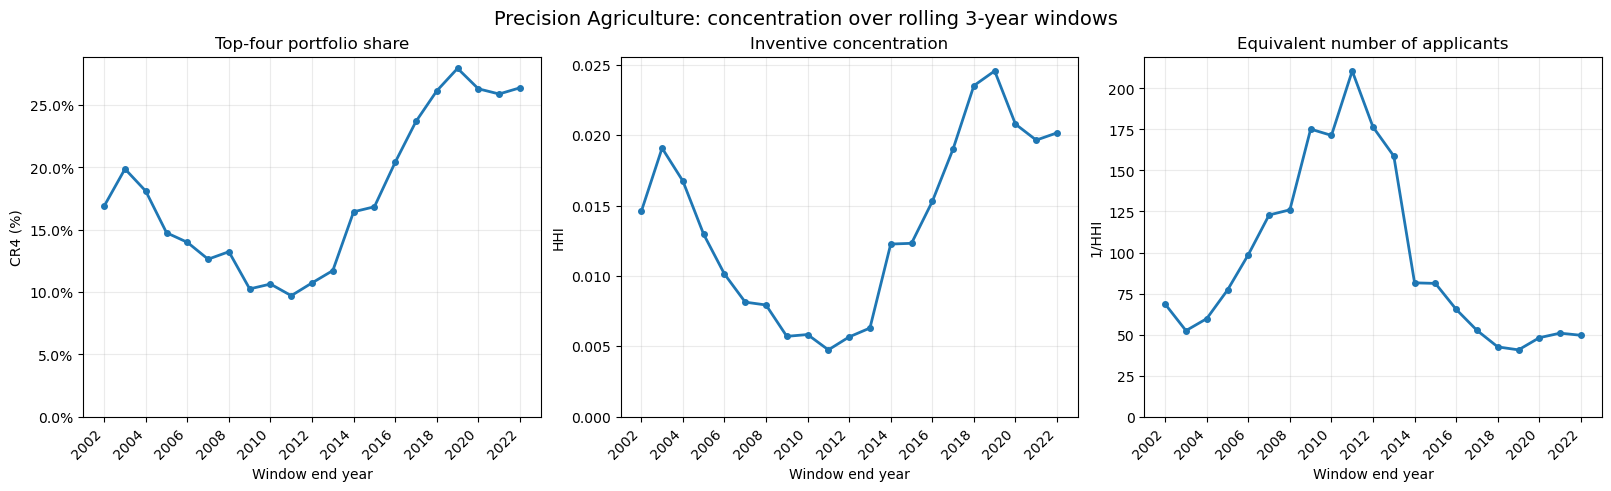

First and last available windows:


,period,applicants,families,CR4 (%),HHI,Equivalent applicants (1/HHI)
end_year,,,,,,
2002,2000–2002,170,179,16.8966,0.0146,68.5971
2022,2020–2022,1051,1771,26.3795,0.0202,49.5996


In [39]:
# Concentration over rolling windows
window_size = int(WINDOW)
final_year = min(YEAR_MAX, LAST_COMPLETE_YEAR)

if window_size < 1:
    raise ValueError("WINDOW must be at least 1.")

rolling_rows = []

for end_year in range(YEAR_MIN + window_size - 1,final_year + 1,):
    start_year = end_year - window_size + 1
    window_links = concentration_links.loc[concentration_links["year"].between(start_year, end_year)]
    if window_links.empty:
        continue
    portfolio_sizes = (window_links.groupby("applicant")["unit_id"].nunique())
    measures = concentration_measures(portfolio_sizes)

    rolling_rows.append({
        "end_year": end_year,
        "period": f"{start_year}–{end_year}",
        "applicants": len(portfolio_sizes),
        "families": window_links["unit_id"].nunique(),
        "CR4 (%)": measures["CR4 (%)"],
        "HHI": measures["HHI"],
        "Equivalent applicants (1/HHI)":
            measures["Equivalent applicants (1/HHI)"],})

if not rolling_rows:
    raise ValueError("No data are available for complete rolling windows.")

concentration_over_time = (pd.DataFrame(rolling_rows).set_index("end_year"))

# Plot with readable integer-year labels
fig, axes = plt.subplots(1, 3,figsize=(16, 4.8),constrained_layout=True,)
years = concentration_over_time.index.to_numpy(dtype=int)

# Display one label every two years, including the final year.
year_ticks = sorted(set(years[::2].tolist() + [int(years[-1])]))

plot_settings = [
    ("CR4 (%)", "Top-four portfolio share", "CR4 (%)"),
    ("HHI", "Inventive concentration", "HHI"),
    (
        "Equivalent applicants (1/HHI)",
        "Equivalent number of applicants",
        "1/HHI",),]

for ax, (column, title, ylabel) in zip(axes, plot_settings):
    ax.plot(
        years,
        concentration_over_time[column],
        marker="o",
        markersize=4,
        linewidth=2,)

    ax.set(
        title=title,
        xlabel="Window end year",
        ylabel=ylabel,)

    ax.set_xticks(year_ticks)
    ax.set_xticklabels(
        [str(year) for year in year_ticks],
        rotation=45,
        ha="right",)

    ax.tick_params(axis="both", labelsize=10)
    ax.grid(alpha=0.25)
    ax.set_ylim(bottom=0)

axes[0].yaxis.set_major_formatter(PercentFormatter(100))
fig.suptitle(f"{SECTOR_NAME}: concentration over rolling " f"{window_size}-year windows",fontsize=14,)

plt.show()

# Compact comparison of the first and last available windows.
print("First and last available windows:")
display(concentration_over_time.iloc[sorted({0, len(concentration_over_time) - 1})].round(4))

### Interpretation

The sector initially shows a more concentrated distribution of inventive
activity than in the following years: a relatively small group of applicants
accounts for a larger share of patent portfolios.

Concentration then declines until approximately the window ending in 2011.
This means that inventive activity becomes more evenly distributed across
applicants.

The trend subsequently reverses. From the window ending in 2012 onwards,
and particularly after 2014, patenting activity becomes increasingly
concentrated. The leading applicants account for a growing share of
inventions, with concentration peaking in 2017–2019.

In the final windows, concentration falls slightly but remains well above
its lowest level. In 2020–2022, the four largest applicants account for
26.4% of applicant–family links, compared with 16.9% in 2000–2002.


## 5. Incumbents and entrants

### 5.1 Leading applicants and their entry into the sector

We classify applicants according to their first observed patent family
in the selected sector:

- **Incumbent:** first observed family before 2013.
- **Entrant:** first observed family in 2013 or later.

The cutoff is controlled by `SPLIT_YEAR`.
Entry refers to the first appearance in our sector dataset, rather than
the organisation's founding date or its first patent in any technological field.

In [40]:
# First and last observed activity within the sector
sector_activity = (
    concentration_links.groupby("applicant")
    .agg(families=("unit_id", "nunique"),first_year=("year", "min"),last_year=("year", "max"),))

recent_portfolios = (concentration_links.loc[concentration_links["year"].ge(SPLIT_YEAR)].groupby("applicant")["unit_id"].nunique())
sector_activity[f"families since {SPLIT_YEAR}"] = (recent_portfolios.reindex(sector_activity.index).fillna(0).astype(int))

sector_activity["status"] = np.where(
    sector_activity["first_year"] < SPLIT_YEAR,
    "incumbent",
    "entrant",)

top_applicants = (
    sector_activity
    .join(applicant_summary[["type", "country"]]).sort_values(["families", "applicant"], ascending=[False, True],))

top_applicants = top_applicants[
    [
        "families",
        "type",
        "country",
        "first_year",
        "last_year",
        f"families since {SPLIT_YEAR}",
        "status",]]

print(f"Classification cutoff: {SPLIT_YEAR}")
print(f"\nTop {TOP_N} applicants:")
display(top_applicants.head(TOP_N))

Classification cutoff: 2013

Top 30 applicants:


,families,type,country,first_year,last_year,families since 2013,status
applicant,,,,,,,
JOHN DEERE,495,firm,US,2000,2022,385,incumbent
CNH,430,firm,US,2000,2022,373,incumbent
KUBOTA,407,firm,JP,2000,2022,391,incumbent
YANMAR,202,firm,JP,2000,2022,194,incumbent
AGCO,123,firm,US,2000,2022,95,incumbent
CLAAS,82,firm,DE,2000,2022,45,incumbent
CLIMATE,79,firm,US,2007,2022,72,incumbent
ISEKI,78,firm,JP,2000,2022,64,incumbent
PRECISION PLANTING,65,firm,US,2007,2022,55,incumbent


### 5.2 Entry and disappearance over time

For each year, we calculate:

- **Active applicants:** applicants with at least one family dated that year.
- **New applicants:** applicants whose first observed family in the sector
  is dated that year.
- **Entrants' family share:** percentage of the year's distinct families
  associated with at least one new applicant.
- **Observed disappearance rate:** percentage of active applicants whose
  last observed family in the sector is dated that year.

Disappearance means no subsequent activity in the observed sector dataset,
rather than confirmed closure of the organisation. We report this rate
only up to three years before the last complete year.

Entry in the first years must be interpreted cautiously: applicants may
have been active before the observation period began in 2000.

In [41]:
# Annual activity, entry and observed disappearance
first_sector_year = (concentration_links.groupby("applicant")["year"].min())
last_sector_year = (concentration_links.groupby("applicant")["year"].max())

annual_activity = (concentration_links[["applicant", "year"]].drop_duplicates().copy())
annual_activity["new_applicant"] = (annual_activity["year"]== annual_activity["applicant"].map(first_sector_year))
annual_activity["last_observed_year"] = (annual_activity["year"]== annual_activity["applicant"].map(last_sector_year))

entry_exit = annual_activity.groupby("year").agg(
    active_applicants=("applicant", "size"),
    new_applicants=("new_applicant", "sum"),
    last_observed_applicants=("last_observed_year", "sum"),)

# Distinct families with at least one applicant entering that year.
entrant_family_mask = (concentration_links["year"]== concentration_links["applicant"].map(first_sector_year))
entrant_families = (concentration_links.loc[entrant_family_mask].groupby("year")["unit_id"].nunique())
annual_families = (concentration_links.groupby("year")["unit_id"].nunique())
entry_exit["entrants_family_share"] = (entrant_families.reindex(entry_exit.index, fill_value=0)/ annual_families* 100)
entry_exit["disappearance_rate"] = (entry_exit["last_observed_applicants"]/ entry_exit["active_applicants"]* 100)

# Allow at least three years of subsequent observation.
observed_end_year = int(concentration_links["year"].max())
disappearance_cutoff = observed_end_year - 3

entry_exit.loc[
    entry_exit.index > disappearance_cutoff,
    "disappearance_rate",] = np.nan

# Annual indicators underlying the entry and disappearance plots.
entry_exit_table = (
    entry_exit.rename(
        columns={
            "new_applicants": "new_to_the_sector",
            "last_observed_applicants": "leaving",
            "disappearance_rate": "rate of disappearance (%)",
            "entrants_family_share": "entrants' share of families (%)",})[
        [
            "active_applicants",
            "new_to_the_sector",
            "leaving",
            "rate of disappearance (%)",
            "entrants' share of families (%)",]].copy())

# Apply the same observation cutoff to the leaving count.
entry_exit_table.loc[entry_exit_table.index > disappearance_cutoff,"leaving",] = pd.NA
entry_exit_table["leaving"] = (entry_exit_table["leaving"].astype("Int64"))

display(
    entry_exit_table.style.format(
        {
            "active_applicants": "{:,.0f}",
            "new_to_the_sector": "{:,.0f}",
            "leaving": "{:,.0f}",
            "rate of disappearance (%)": "{:.1f}",
            "entrants' share of families (%)": "{:.1f}",},na_rep="—",))


,active_applicants,new_to_the_sector,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,
2000,56,56,30,53.6,100.0
2001,84,69,59,70.2,64.4
2002,62,45,38,61.3,63.6
2003,66,50,36,54.5,60.7
2004,85,64,46,54.1,69.4
2005,109,84,70,64.2,70.2
2006,92,69,67,72.8,63.3
2007,149,127,115,77.2,81.8
2008,113,88,75,66.4,79.7


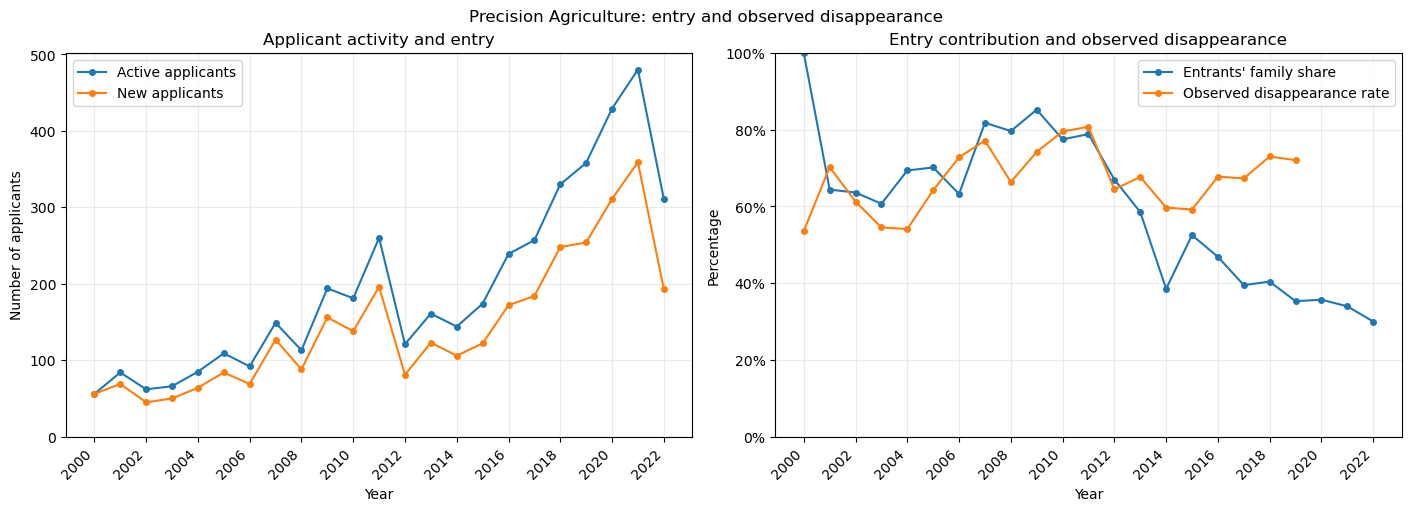

In [42]:
# Plots
fig, axes = plt.subplots(1, 2,figsize=(14, 5),constrained_layout=True,)

axes[0].plot(
    entry_exit.index,
    entry_exit["active_applicants"],
    marker="o",
    markersize=4,
    label="Active applicants",)

axes[0].plot(
    entry_exit.index,
    entry_exit["new_applicants"],
    marker="o",
    markersize=4,
    label="New applicants",)

axes[0].set(
    title="Applicant activity and entry",
    xlabel="Year",
    ylabel="Number of applicants",)

axes[1].plot(
    entry_exit.index,
    entry_exit["entrants_family_share"],
    marker="o",
    markersize=4,
    label="Entrants' family share",)

axes[1].plot(
    entry_exit.index,
    entry_exit["disappearance_rate"],
    marker="o",
    markersize=4,
    label="Observed disappearance rate",)

axes[1].set(
    title="Entry contribution and observed disappearance",
    xlabel="Year",
    ylabel="Percentage",
    ylim=(0, 100),)

axes[1].yaxis.set_major_formatter(PercentFormatter(100))

years = entry_exit.index.to_numpy(dtype=int)
year_ticks = sorted(set(years[::2].tolist() + [int(years[-1])]))

for ax in axes:
    ax.set_xticks(year_ticks)
    ax.set_xticklabels(
        [str(year) for year in year_ticks],
        rotation=45,
        ha="right",)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(f"{SECTOR_NAME}: entry and observed disappearance")
plt.show()

### Interpretation

The sector attracts an increasing number of applicants, particularly
after 2015. Both active applicants and first-time participants increase,
reaching their highest observed counts in 2021.

However, more entrants do not translate into a larger contribution to
inventive activity. The share of families associated with new applicants
falls from around 80% in several years before 2012 to approximately 30%
in 2022. Applicants already present in the sector therefore account for
a growing share of inventions.

Together with the concentration indicators, this suggests a sector
that continues to attract participants while inventive activity becomes
increasingly centred on established applicants.

Observed disappearance is also high: many applicants have no subsequent
family recorded in the sector. This may reflect occasional patenting
or activity outside the selected field, rather than organisational closure.

The 100% entrants' family share in 2000 is mechanical because this is
the first observation year.

### 5.3 New to the sector versus new to patenting

An applicant entering Precision Agriculture may already have patented
in another technological field.

We retrieve the earliest filing year available in PATSTAT for each standardised applicant identifier (`psn_id`)
represented in our sector data, without restricting the technology.

For each harmonised applicant, we take the earliest year across its associated identifiers.

An applicant is classified as **new to patenting** in a year when its
first observed sector family and its earliest retrieved filing year
both coincide with that year.

In [43]:
# Earliest filing year in any field
psn_ids = sorted({int(value)
    for value in raw_sector["psn_id"].dropna().unique()
    if int(value) > 0})

first_patent_parts = []
batch_size = 1000

for start in range(0, len(psn_ids), batch_size):
    batch = psn_ids[start:start + batch_size]

    q_first = (
        db.query(
            TLS206_PERSON.psn_id,
            func.min(
                TLS201_APPLN.earliest_filing_year
            ).label("first_patent_year"),)
        .join(
            TLS207_PERS_APPLN,
            TLS207_PERS_APPLN.person_id
            == TLS206_PERSON.person_id,)
        .join(
            TLS201_APPLN,
            TLS201_APPLN.appln_id
            == TLS207_PERS_APPLN.appln_id,)
        .filter(
            TLS206_PERSON.psn_id.in_(batch),
            TLS207_PERS_APPLN.applt_seq_nr > 0,
            TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX),
        ).group_by(TLS206_PERSON.psn_id))

    first_patent_parts.append(patstat.df(q_first))

if not first_patent_parts:
    raise ValueError("No valid applicant identifiers were found.")

first_patents = pd.concat(first_patent_parts,ignore_index=True,)

# Use the final sector assignments already established.
identifier_links = (
    applicant_records[["psn_id", "applicant"]]
    .drop_duplicates()
    .merge(
        first_patents,
        on="psn_id",
        how="left",
        validate="many_to_one",))

first_ever = (identifier_links.groupby("applicant")["first_patent_year"].min())

print("Applicants with a retrieved first filing year:",f"{first_ever.notna().sum():,}",)
print("Applicants without a retrieved first filing year:",f"{first_ever.isna().sum():,}",)

Applicants with a retrieved first filing year: 3,295
Applicants without a retrieved first filing year: 0


In [44]:
annual_activity["first_patent_year"] = (annual_activity["applicant"].map(first_ever))
annual_activity["new_to_patenting"] = (
    annual_activity["new_applicant"] & annual_activity["year"].eq(annual_activity["first_patent_year"]))

new_to_patenting = (annual_activity.groupby("year")["new_to_patenting"].sum())

entry_exit["new_to_patenting"] = (new_to_patenting.reindex(entry_exit.index, fill_value=0).astype(int))

entry_exit_table["new_to_patenting"] = (entry_exit["new_to_patenting"])

entry_exit_table = entry_exit_table[
    [
        "active_applicants",
        "new_to_the_sector",
        "new_to_patenting",
        "leaving",
        "rate of disappearance (%)",
        "entrants' share of families (%)",]]

display(
    entry_exit_table.style.format(
        {
            "active_applicants": "{:,.0f}",
            "new_to_the_sector": "{:,.0f}",
            "new_to_patenting": "{:,.0f}",
            "leaving": "{:,.0f}",
            "rate of disappearance (%)": "{:.1f}",
            "entrants' share of families (%)": "{:.1f}",},na_rep="—",))

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2000,56,56,24,30,53.6,100.0
2001,84,69,38,59,70.2,64.4
2002,62,45,25,38,61.3,63.6
2003,66,50,23,36,54.5,60.7
2004,85,64,37,46,54.1,69.4
2005,109,84,48,70,64.2,70.2
2006,92,69,35,67,72.8,63.3
2007,149,127,71,115,77.2,81.8
2008,113,88,46,75,66.4,79.7


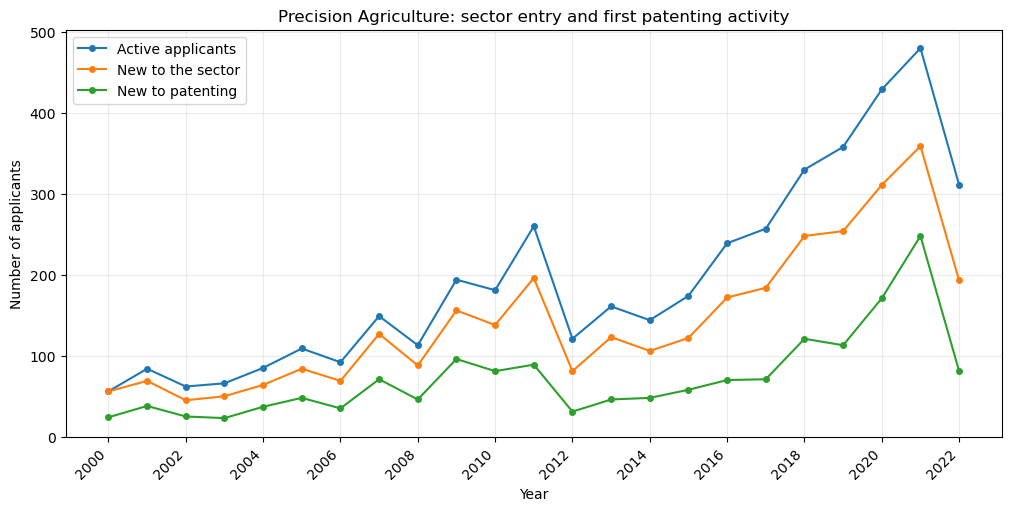

In [45]:
fig, ax = plt.subplots(figsize=(10, 5),constrained_layout=True,)

for column, label in [
    ("active_applicants", "Active applicants"),
    ("new_applicants", "New to the sector"),
    ("new_to_patenting", "New to patenting"),]:
    ax.plot(
        entry_exit.index,
        entry_exit[column],
        marker="o",
        markersize=4,
        label=label,)

years = entry_exit.index.to_numpy(dtype=int)
year_ticks = sorted(set(years[::2].tolist() + [int(years[-1])]))

ax.set_xticks(year_ticks)
ax.set_xticklabels(
    [str(year) for year in year_ticks],
    rotation=45,
    ha="right",)

ax.set(
    title=f"{SECTOR_NAME}: sector entry and first patenting activity",
    xlabel="Year",
    ylabel="Number of applicants",
    ylim=(0, None),)

ax.grid(alpha=0.25)
ax.legend()
plt.show()

### Interpretation
Growth in Precision Agriculture involves both first-time patent applicants
and applicants entering from previous patenting activity in other fields.

The number of applicants new to patenting remains below the number new
to the sector. Sector entry therefore includes a substantial component
of applicants with an existing patenting history. For example, in 2013,
123 applicants first appear in the sector, while 46 are classified as
new to patenting.

Both forms of entry increase strongly after 2015 and peak in 2021.
The sector thus continues to attract participants with different levels
of prior patenting experience.

However, increasing entry does not imply increasing influence over
inventive output. Combined with the declining entrants' family share
shown previously, these results suggest that established sector
participants account for a growing share of inventions despite
continued entry.

The high observed disappearance rates indicate that many applicants
do not record subsequent activity in the selected sector. They do not
demonstrate organisational closure or commercial failure.

## 6. Growth of technological areas

We analyse all CPC codes attached to the patent families selected in
Step 0, including technologies outside the original search prefixes.

We retain the full CPC symbols rather than aggregating them into main
groups. We compare distinct family counts in 2013–2017 and 2018–2022.

Each family is counted once per CPC code, but can appear under several
codes. Counts therefore overlap. Parent groups and their subgroups are
not mutually exclusive technological areas.

The table reports family counts, absolute growth, percentage growth,
and the percentage of all selected families associated with each code
in each period. Changes in these percentages show whether a code gains
or loses weight within the expanding sector.

Codes with a main-group number of 2000 or above and section Y codes
are displayed separately as supplementary classifications, rather than
mixed into the primary technological ranking.

In [48]:
# All CPC codes at their original level of detail
period_end = min(YEAR_MAX, LAST_COMPLETE_YEAR)
recent_start = period_end - 4
earlier_end = recent_start - 1
earlier_start = earlier_end - 4

if earlier_start < YEAR_MIN:
    raise ValueError("Ten years are required for this comparison.")

earlier_label = f"{earlier_start}–{earlier_end}"
recent_label = f"{recent_start}–{period_end}"

cpc_column = next(
    (
        column
        for column in ("cpc", "cpc_class_symbol")
        if column in family_cpc.columns),None,)

if cpc_column is None:
    raise ValueError("No CPC column was found in family_cpc.")

cpc_detail = family_cpc[["unit_id", cpc_column]].copy()

cpc_detail["cpc_code"] = (cpc_detail[cpc_column].astype("string").str.upper().str.replace(r"\s+", "", regex=True))

valid_code = cpc_detail["cpc_code"].str.fullmatch(r"[A-HY]\d{2}[A-Z]\d+/\d+",na=False,)

cpc_detail = (
    cpc_detail.loc[valid_code, ["unit_id", "cpc_code"]].drop_duplicates()
    .merge(
        fam[["unit_id", "year"]].drop_duplicates(),
        on="unit_id",
        how="inner",
        validate="many_to_one",))

# Keep the original symbol, including every digit after the slash.
earlier_counts = (
    cpc_detail.loc[
        cpc_detail["year"].between(earlier_start, earlier_end)
    ].groupby("cpc_code")["unit_id"].nunique().rename(earlier_label))

recent_counts = (
    cpc_detail.loc[
        cpc_detail["year"].between(recent_start, period_end)
    ].groupby("cpc_code")["unit_id"].nunique().rename(recent_label))

cpc_growth = (pd.concat([earlier_counts, recent_counts], axis=1).fillna(0).astype(int))
cpc_growth["absolute_change"] = (cpc_growth[recent_label] - cpc_growth[earlier_label])
cpc_growth["growth (%)"] = (cpc_growth["absolute_change"].div(cpc_growth[earlier_label].replace(0, np.nan))* 100)

# Denominators include all selected families in each period.
earlier_total = fam.loc[fam["year"].between(earlier_start, earlier_end),"unit_id",].nunique()
recent_total = fam.loc[fam["year"].between(recent_start, period_end),"unit_id",].nunique()

cpc_growth[f"share {earlier_label} (%)"] = (cpc_growth[earlier_label] / earlier_total * 100)
cpc_growth[f"share {recent_label} (%)"] = (cpc_growth[recent_label] / recent_total * 100)

cpc_growth["share change (pp)"] = (cpc_growth[f"share {recent_label} (%)"]- cpc_growth[f"share {earlier_label} (%)"])

# Separate supplementary codes while retaining them in the analysis.
main_group_number = (cpc_growth.index.to_series().str.extract(r"^[A-HY]\d{2}[A-Z](\d+)/", expand=False).astype(int))
supplementary_mask = (main_group_number.ge(2000) | cpc_growth.index.to_series().str.startswith("Y"))
cpc_growth = cpc_growth.sort_values([recent_label, "absolute_change"],ascending=[False, False],)

technology_growth = cpc_growth.loc[~supplementary_mask.reindex(cpc_growth.index)].copy()
supplementary_growth = cpc_growth.loc[supplementary_mask.reindex(cpc_growth.index)].copy()

print("Largest technological CPC codes in the recent period:")
display(technology_growth.head(20).round(1))
print("\nSupplementary CPC codes — shown separately:")
display(supplementary_growth.head(10).round(1))

# Avoid ranking tiny initial counts as the strongest growth.
MIN_BASELINE_FAMILIES = 10

fastest_growing = (
    technology_growth.loc[
        technology_growth[earlier_label].ge(
            MIN_BASELINE_FAMILIES)].sort_values(["growth (%)", "absolute_change"],ascending=[False, False],))

print("\nFastest-growing technological codes " f"with at least {MIN_BASELINE_FAMILIES} " f"families in {earlier_label}:")
display(fastest_growing.head(15).round(1))

Largest technological CPC codes in the recent period:


,2013–2017,2018–2022,absolute_change,growth (%),share 2013–2017 (%),share 2018–2022 (%),share change (pp)
cpc_code,,,,,,,
A01B79/005,537,1165,628,116.9,40.0,39.8,-0.3
A01B69/008,379,984,605,159.6,28.2,33.6,5.3
G06Q50/02,144,324,180,125.0,10.7,11.1,0.3
A01B69/001,45,237,192,426.7,3.4,8.1,4.7
G06V20/188,40,224,184,460.0,3.0,7.6,4.7
A01M7/0089,52,220,168,323.1,3.9,7.5,3.6
A01G25/167,124,198,74,59.7,9.2,6.8,-2.5
A01D41/127,66,192,126,190.9,4.9,6.6,1.6
G05D1/648,27,185,158,585.2,2.0,6.3,4.3



Supplementary CPC codes — shown separately:


,2013–2017,2018–2022,absolute_change,growth (%),share 2013–2017 (%),share 2018–2022 (%),share change (pp)
cpc_code,,,,,,,
G05D2105/15,63,331,268,425.4,4.7,11.3,6.6
G05D2107/21,58,314,256,441.4,4.3,10.7,6.4
G05D2109/10,60,305,245,408.3,4.5,10.4,5.9
G06T2207/30188,31,158,127,409.7,2.3,5.4,3.1
Y02A40/10,136,157,21,15.4,10.1,5.4,-4.8
B60Y2200/22,9,88,79,877.8,0.7,3.0,2.3
Y02A40/22,55,76,21,38.2,4.1,2.6,-1.5
G05D2101/10,15,58,43,286.7,1.1,2.0,0.9
B60W2300/15,8,55,47,587.5,0.6,1.9,1.3



Fastest-growing technological codes with at least 10 families in 2013–2017:


,2013–2017,2018–2022,absolute_change,growth (%),share 2013–2017 (%),share 2018–2022 (%),share change (pp)
cpc_code,,,,,,,
G05D1/648,27,185,158,585.2,2.0,6.3,4.3
G06N3/08,10,58,48,480.0,0.7,2.0,1.2
G06V20/188,40,224,184,460.0,3.0,7.6,4.7
A01B69/001,45,237,192,426.7,3.4,8.1,4.7
A01B63/1112,11,55,44,400.0,0.8,1.9,1.1
A01B49/027,16,79,63,393.8,1.2,2.7,1.5
A01D41/1278,34,165,131,385.3,2.5,5.6,3.1
G05D1/0088,16,73,57,356.2,1.2,2.5,1.3
A01M7/0089,52,220,168,323.1,3.9,7.5,3.6


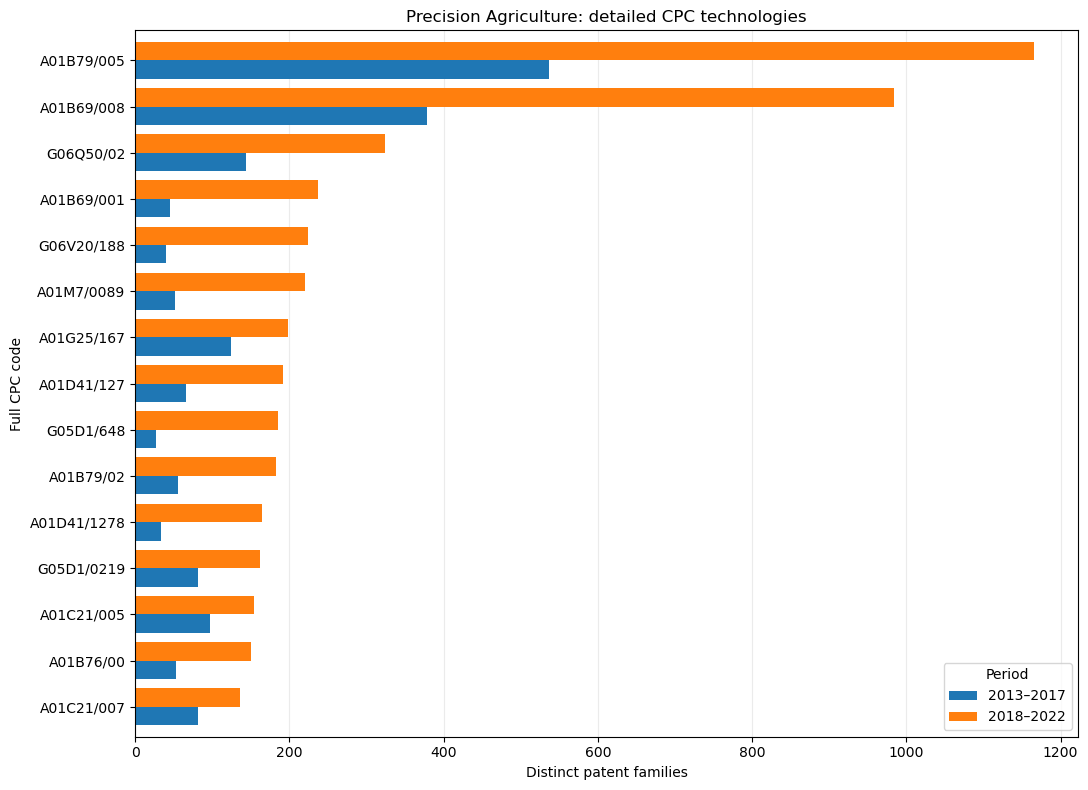

In [49]:
# Largest detailed technological codes
plot_data = (technology_growth.head(15)[[earlier_label, recent_label]].sort_values(recent_label))

ax = plot_data.plot.barh(figsize=(11, 8),width=0.8,)

ax.set(
    title=f"{SECTOR_NAME}: detailed CPC technologies",
    xlabel="Distinct patent families",
    ylabel="Full CPC code",)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Period")

plt.tight_layout()
plt.show()

### Interpretation
The results highlight both the largest technological areas and those
gaining importance within Precision Agriculture.

The volume comparison is led by A01B79/005, the broad **precision-agriculture**
code, and A01B69/008, covering ***automatic guidance of agricultural vehicles**.
Automatic guidance therefore represents a substantial area of inventive
activity, alongside sector-specific ICT applications (G06Q50/02).

Within this landscape, technologies that help machines perceive their
surroundings are expanding particularly quickly. **Optically assisted
agricultural guidance** (A01B69/001) increases from 45 to 237 families,
while **vegetation recognition in images** (G06V20/188) rises from 40 to 224.
Their shares of selected families increase from 3.4% to 8.1% and from
3.0% to 7.6%, respectively. They therefore gain importance even after
accounting for the sector's overall growth.

**Spraying regulation** and **control systems** (A01M7/0089) also become more
prominent, increasing from 52 to 220 families and from 3.9% to 7.5%
of selected families. The volume ranking additionally highlights
moisture-based irrigation control (A01G25/167) and control or measurement
systems for combine harvesters (A01D41/127), showing that inventive activity
extends across several agricultural operations.

**Neural-network learning methods** (G06N3/08) grow by 480%, but from only
10 to 58 families. This illustrates why percentage growth and technological
scale should be considered together: a rapidly growing area may still
have a relatively small patent portfolio.

Overall, the findings suggest increasing emphasis on automatic guidance,
machine perception, and the control of agricultural operations.
These patterns are consistent with more automated and responsive
agricultural machinery, although patent counts alone do not establish
commercial adoption or integration of these technologies.

### Technological size and growth map

The map shows the 15 largest detailed technological CPC codes in
2018–2022, among those with at least ten families in 2013–2017.

Each point represents a code: its horizontal position indicates recent
family volume, while its vertical position indicates percentage growth.

The upper-right area identifies technologies combining substantial
recent activity with rapid growth. This is a comparison of the largest
eligible codes, rather than an exhaustive map of all technologies.

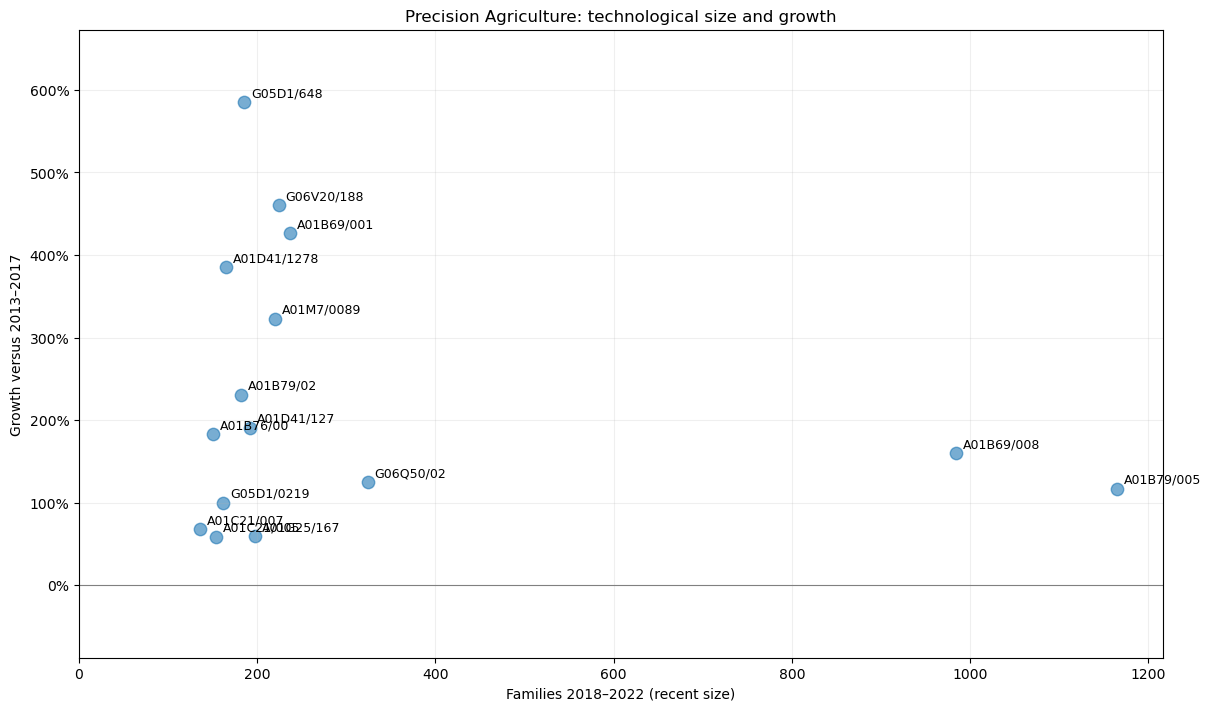

In [50]:

# Select the 15 largest eligible technological codes.
plot = (
    technology_growth.loc[
        technology_growth[earlier_label].ge(
            MIN_BASELINE_FAMILIES) & technology_growth["growth (%)"].notna()].nlargest(15, recent_label))

fig, ax = plt.subplots(figsize=(12, 7),constrained_layout=True,)

ax.scatter(
    plot[recent_label],
    plot["growth (%)"],
    s=80,
    alpha=0.6,)

for name, row in plot.iterrows():
    ax.annotate(
        name,
        (row[recent_label], row["growth (%)"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=9,)

ax.axhline(0, color="grey", linewidth=0.8)

ax.set(
    title=f"{SECTOR_NAME}: technological size and growth",
    xlabel=f"Families {recent_label} (recent size)",
    ylabel=f"Growth versus {earlier_label}",)

ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlim(left=0)
ax.margins(x=0.15, y=0.15)
ax.grid(alpha=0.2)

plt.show()

## 7. Additional concentration analyses

### 7.1 Lorenz curve of applicant portfolios

The Lorenz curve shows how unevenly patent portfolios are distributed
across applicants.

Applicants are ordered from the smallest to the largest portfolio.
The horizontal axis reports their cumulative percentage; the vertical
axis reports their cumulative percentage of applicant–family links.

The diagonal represents equal portfolio sizes. A curve further below
the diagonal indicates greater inequality.

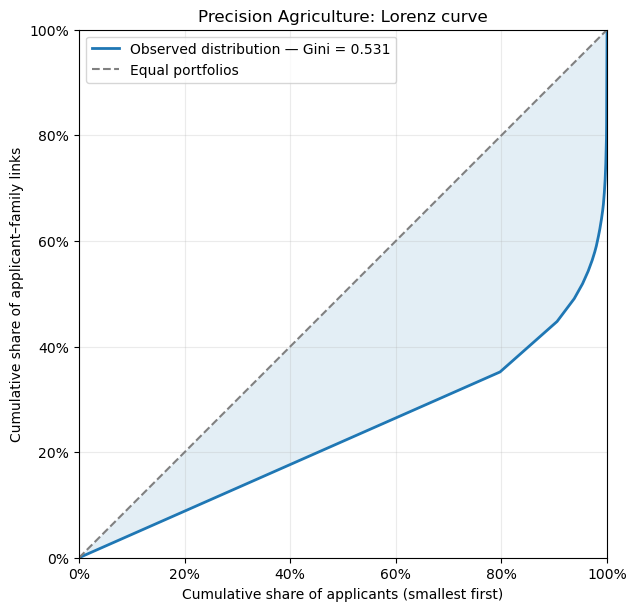

In [51]:
# Lorenz curve: all applicants
portfolio_sizes = np.sort(families_per_applicant.to_numpy(dtype=float))
applicant_share = (np.arange(len(portfolio_sizes) + 1)/ len(portfolio_sizes)* 100)
portfolio_share = np.concatenate([[0],np.cumsum(portfolio_sizes) / portfolio_sizes.sum() * 100,])

overall_gini = concentration_measures(portfolio_sizes)["Gini"]

fig, ax = plt.subplots(figsize=(7, 6),constrained_layout=True,)

ax.plot(
    applicant_share,
    portfolio_share,
    linewidth=2,
    label=f"Observed distribution — Gini = {overall_gini:.3f}",)

ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="grey",
    label="Equal portfolios",)

ax.fill_between(
    applicant_share,
    portfolio_share,
    applicant_share,
    alpha=0.12,)

ax.set(
    title=f"{SECTOR_NAME}: Lorenz curve",
    xlabel="Cumulative share of applicants (smallest first)",
    ylabel="Cumulative share of applicant–family links",
    xlim=(0, 100),
    ylim=(0, 100),)

ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_aspect("equal")
ax.grid(alpha=0.25)
ax.legend()

plt.show()

### Interpretation
Patent portfolios are unevenly distributed across applicants.
The 80% of applicants with the smallest portfolios account for approximately
35% of applicant–family links, while the largest 20% account for the
remaining 65%.

The steep rise near the right-hand end shows that a small fraction of
applicants holds particularly large portfolios. The nearly straight
initial segment is consistent with many applicants having similarly
small portfolios.

The Gini coefficient of 0.535 summarises this inequality. Together,
the curve and the coefficient show that the sector's large number of
participants does not imply an even distribution of inventive activity.

### 7.2 Firm portfolios by country

Each harmonised firm is assigned its most frequent known PATSTAT country,
as established in the final applicant table. This is an analytical
assignment rather than verified headquarters location.

For each country, we report the number of firms, distinct families,
and the distribution of firm portfolio sizes.

A family associated with several firms in the same country is counted
once in the country's distinct-family total, but once per firm in
applicant–family links. Families may also appear in several countries.

Concentration indicators are calculated from firm portfolios within
each country. They describe the distribution of inventive activity
among the observed firms, not the country's share of the global market.

In [52]:
# Firms with a known country
firm_metadata = (
    applicant_summary.loc[
        applicant_summary["type"].eq("firm"),
        ["country"],].copy())

firm_metadata["country"] = (firm_metadata["country"].astype("string").str.strip().str.upper())
known_country = (firm_metadata["country"].notna()& ~firm_metadata["country"].isin(["", "UNKNOWN", "NAN", "NONE", "<NA>"]))
firm_metadata = firm_metadata.loc[known_country]

firm_country_links = concentration_links.merge(
    firm_metadata,
    left_on="applicant",
    right_index=True,
    how="inner",
    validate="many_to_one",)

firm_portfolios_by_country = (firm_country_links.groupby(["country", "applicant"])["unit_id"].nunique().rename("families").reset_index())

country_summary = (
    firm_portfolios_by_country.groupby("country")
    .agg(
        firms=("applicant", "nunique"),
        applicant_family_links=("families", "sum"),
        mean_portfolio=("families", "mean"),
        median_portfolio=("families", "median"),
        smallest_portfolio=("families", "min"),
        largest_portfolio=("families", "max"),))

country_summary["distinct_families"] = (firm_country_links.groupby("country")["unit_id"].nunique())
country_summary = country_summary[
    [
        "firms",
        "distinct_families",
        "applicant_family_links",
        "mean_portfolio",
        "median_portfolio",
        "smallest_portfolio",
        "largest_portfolio",]].sort_values("distinct_families", ascending=False)

all_sector_firms = applicant_summary.index[applicant_summary["type"].eq("firm")]
represented_firms = (firm_country_links["applicant"].nunique())
active_sector_firms = concentration_links.loc[concentration_links["applicant"].isin(all_sector_firms),"applicant",].nunique()

print(f"Firms in the selected period: {active_sector_firms:,}")
print(f"Firms included in the country analysis: {represented_firms:,}")
print("Firms excluded because country is missing:",f"{active_sector_firms - represented_firms:,}",)
print("\nFirm portfolios by country:")
display(country_summary.head(15).round(2))

Firms in the selected period: 989
Firms included in the country analysis: 622
Firms excluded because country is missing: 367

Firm portfolios by country:


,firms,distinct_families,applicant_family_links,mean_portfolio,median_portfolio,smallest_portfolio,largest_portfolio
country,,,,,,,
US,233,1803,1979,8.49,1.0,1,495
JP,25,746,758,30.32,2.0,1,407
DE,44,297,335,7.61,1.0,1,82
CA,44,99,104,2.36,1.0,1,14
KR,39,68,69,1.77,1.0,1,17
FR,24,57,62,2.58,1.0,1,15
AU,35,45,50,1.43,1.0,1,4
CN,16,36,41,2.56,2.0,1,11
CH,14,30,32,2.29,1.0,1,14


### Interpretation
The United States leads the firm-based comparison, with 234 firms and
1,803 distinct families. Its portfolio distribution is uneven: the median
firm has one family, while the mean is 8.47, indicating many small
portfolios alongside a few large ones.

Japan has a different structure. Only 25 firms account for 746 distinct
families, and the mean portfolio reaches 30.32 families. The largest firm
alone represents approximately 54% of Japanese applicant–family links,
suggesting substantial concentration around a leading applicant.

Germany ranks third by family volume. Canada and South Korea have
relatively many firms but smaller portfolios, while Australia and the
United Kingdom show particularly small portfolio sizes.

These results describe firms assigned to each country, rather than all
national inventive activity. Universities, individuals and applicants
classified as unknown are excluded. This is particularly relevant when
interpreting China's relatively low firm-based count.

### Geographical distribution of inventive activity

The maps distinguish two dimensions:

- **Inventive volume:** distinct families associated with firms assigned
  to each country.
- **Within-country concentration:** the HHI of firm portfolios within
  each country, shown only where at least ten firms are observed.

Country assignments use the most frequent known PATSTAT applicant country.
They do not identify the location of research activity or patent protection.

A family associated with firms in different countries may contribute
to more than one country's volume. Grey countries have no mapped value,
which should not be interpreted automatically as zero activity.

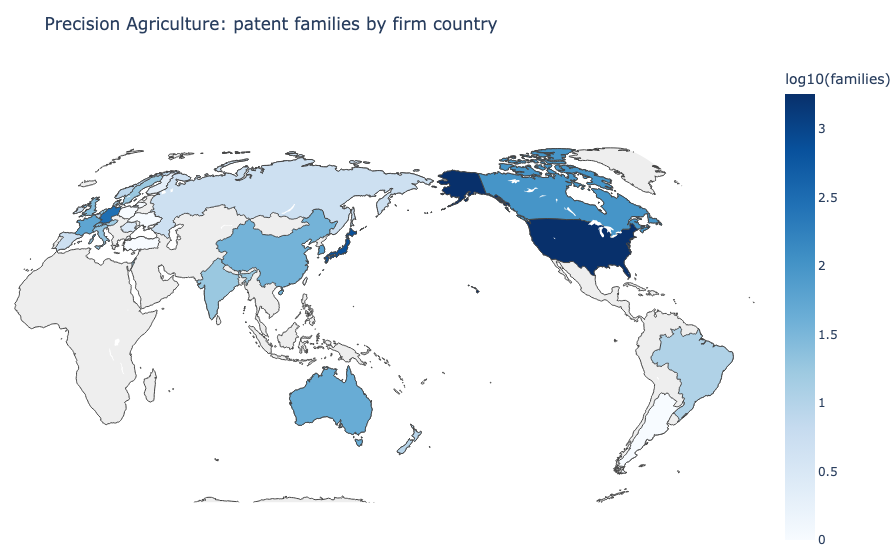

In [53]:
import plotly.express as px

# Convert PATSTAT two-letter country codes to ISO three-letter codes.
def to_iso3(code):
    code = str(code).strip().upper()
    # Common alternative codes.
    code = {"UK": "GB", "EL": "GR"}.get(code, code)
    country = pycountry.countries.get(alpha_2=code)
    return country.alpha_3 if country else None

map_data = country_summary.reset_index().copy()
map_data["iso3"] = map_data["country"].map(to_iso3)

unmapped = map_data.loc[map_data["iso3"].isna(), "country"].tolist()
if unmapped:
    print("Country codes not mapped:", ", ".join(unmapped))

map_data = map_data.dropna(subset=["iso3"]).copy()

# Logarithmic colour scaling keeps smaller portfolios visible.
map_data["colour_value"] = np.log10(map_data["distinct_families"])

fig = px.choropleth(
    map_data,
    locations="iso3",
    locationmode="ISO-3",
    color="colour_value",
    hover_name="country",
    hover_data={
        "iso3": False,
        "colour_value": False,
        "distinct_families": ":,.0f",
        "firms": ":,.0f",
    },
    color_continuous_scale="Blues",
    labels={
        "distinct_families": "Distinct families",
        "firms": "Firms",
        "colour_value": "log10(families)",
    },
    title=f"{SECTOR_NAME}: patent families by firm country",)

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    showland=True,
    landcolor="#eeeeee",
    projection_type="natural earth",
)

fig.update_layout(height=550,margin=dict(l=0, r=0, t=60, b=0),)
fig.show()

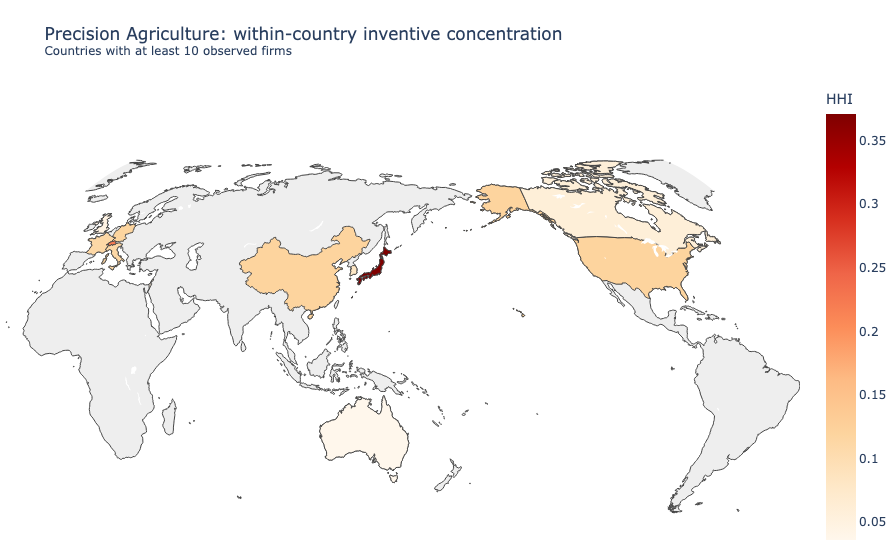

In [54]:
# Calculate HHI for every country, not only the top twelve.
country_hhi = (
    firm_portfolios_by_country.groupby("country")["families"]
    .apply(lambda sizes:np.square(sizes / sizes.sum()).sum()).rename("HHI"))

hhi_map_data = (
    map_data.merge(
        country_hhi,
        left_on="country",
        right_index=True,
        validate="one_to_one",
    ).loc[lambda frame: frame["firms"].ge(10)].copy())

fig = px.choropleth(
    hhi_map_data,
    locations="iso3",
    locationmode="ISO-3",
    color="HHI",
    hover_name="country",
    hover_data={
        "iso3": False,
        "HHI": ":.4f",
        "firms": ":,.0f",
        "distinct_families": ":,.0f",},
    color_continuous_scale="OrRd",
    labels={
        "firms": "Firms",
        "distinct_families": "Distinct families",},
    title=(
        f"{SECTOR_NAME}: within-country inventive concentration"
        "<br><sup>Countries with at least 10 observed firms</sup>"),)

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    showland=True,
    landcolor="#eeeeee",
    projection_type="natural earth",)

fig.update_layout(height=550,margin=dict(l=0, r=0, t=80, b=0),)
fig.show()

### 7.3 Concentration within countries

We compare the 12 countries with the largest numbers of distinct families
associated with firms. The selection is based on inventive volume,
rather than on concentration scores.

The same concentration formulas are applied separately within each
country. Shares are calculated relative to the sum of firm portfolios
in that country.

CR4 equals 100% whenever a country has four or fewer observed firms;
CR8 does the same with eight or fewer firms. High values in small
samples should therefore be interpreted cautiously.

In [55]:
# Concentration in the 12 largest countries by family volume
selected_countries = country_summary.head(12).index.tolist()
country_measure_rows = []

for country in selected_countries:
    sizes = firm_portfolios_by_country.loc[
        firm_portfolios_by_country["country"].eq(country),
        "families",]
    measures = concentration_measures(sizes)
    country_measure_rows.append({
        "country": country,
        "firms": measures["Applicants"],
        "distinct families":
            country_summary.loc[country, "distinct_families"],
        "CV": measures["CV"],
        "CR4 (%)": measures["CR4 (%)"],
        "CR8 (%)": measures["CR8 (%)"],
        "HHI": measures["HHI"],
        "1/HHI": measures["Equivalent applicants (1/HHI)"],
        "Gini": measures["Gini"],
        "Lotka slope": measures["Lotka slope"],
        "Lotka p-value": measures["Lotka p-value"],})

country_concentration = (pd.DataFrame(country_measure_rows).set_index("country"))
display(country_concentration.round(4))

,firms,distinct families,CV,CR4 (%),CR8 (%),HHI,1/HHI,Gini,Lotka slope,Lotka p-value
country,,,,,,,,,,
US,233,1803,5.1973,56.9480,67.7615,0.1197,8.3523,0.8192,-0.6432,0.0000
JP,25,746,2.9353,92.6121,96.5699,0.3708,2.6965,0.8634,-0.2530,0.0446
DE,44,297,2.0744,60.0000,80.2985,0.1183,8.4526,0.7291,-0.5053,0.0055
CA,44,99,1.2744,41.3462,54.8077,0.0588,17.0063,0.4594,-1.1091,0.0246
KR,39,68,1.4868,40.5797,52.1739,0.0809,12.3662,0.3842,-1.1682,0.0555
FR,24,57,1.3259,58.0645,72.5806,0.1119,8.9395,0.5013,-0.9269,0.0242
AU,35,45,0.5173,24.0000,40.0000,0.0360,27.7778,0.2251,-2.3289,0.0143
CN,16,36,0.9869,51.2195,70.7317,0.1196,8.3632,0.3582,-0.8353,0.2029
CH,14,30,1.5100,68.7500,81.2500,0.2227,4.4912,0.4821,-0.6829,0.2975


### Interpretation
Japan shows the strongest concentration among the countries compared.
Its four largest firms account for 92.6% of applicant–family links,
and its HHI corresponds to approximately 2.7 equally sized firms.
Inventive activity is therefore concentrated around very few applicants.

The United States combines the largest inventive volume with substantial
portfolio inequality. Although 234 firms are observed, the four largest
account for 56.9% of applicant–family links. The Gini coefficient of 0.819
indicates a strong contrast between leading firms and numerous small
portfolio holders.

Germany has an HHI close to that of the United States, but a lower Gini.
The indicators therefore capture different features: similar overall
concentration can coexist with different degrees of portfolio inequality.

Australia, the United Kingdom and Israel have more evenly distributed,
generally small portfolios. This describes the distribution of observed
patenting, rather than stronger innovative performance or easier entry.

Small samples require particular caution. The Netherlands has only
eight firms, so its CR8 is necessarily 100%. Lotka estimates are unavailable
for the United Kingdom and Israel because fewer than three distinct
portfolio sizes are observed; other estimates may also rely on few points.

Overall, the country comparison reveals different structures of inventive
activity, rather than a single ranking of national technological strength.
Results cover firms only and depend on the country assignments and
harmonisation used in the analysis.